In [1]:
import pandas as pd
from pathlib import Path

# Crée le dossier des graphiques s'il n'existe pas
Path("../figures").mkdir(exist_ok=True)

# Charger les données nettoyées
df = pd.read_csv(
    "../data/processed/retail_store_sales_clean.csv",
    parse_dates=["Transaction Date"]
)

# Vérifier le chargement
print("Dimensions du jeu de données :", df.shape)
display(df.head())

Dimensions du jeu de données : (12575, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


# 1. Analyse des données

Cette partie a pour objectif d'analyser les données nettoyées afin d'étudier les ventes, les produits, les clients et leur évolution dans le temps.

## 1.1 Indicateurs généraux des ventes

In [2]:
# Calcul des indicateurs généraux

nb_transactions = df["Transaction ID"].nunique()
nb_clients = df["Customer ID"].nunique()
nb_categories = df["Category"].nunique()

chiffre_affaires = df["Total Spent"].sum()
panier_moyen = df["Total Spent"].mean()
quantite_totale = df["Quantity"].sum()

print("Nombre de transactions :", nb_transactions)
print("Nombre de clients :", nb_clients)
print("Nombre de catégories :", nb_categories)
print("Chiffre d'affaires total :", round(chiffre_affaires, 2))
print("Montant moyen par transaction :", round(panier_moyen, 2))
print("Quantité totale vendue :", quantite_totale)

Nombre de transactions : 12575
Nombre de clients : 25
Nombre de catégories : 8
Chiffre d'affaires total : 1552071.0
Montant moyen par transaction : 129.65
Quantité totale vendue : 66276.0


**Interprétation des indicateurs généraux**

L'analyse générale montre que le jeu de données contient 12 575 transactions, réalisées par 25 clients et réparties dans 8 catégories. Le chiffre d'affaires connu s'élève à 1 552 071, avec un panier moyen de 129,65. La quantité totale vendue est de 66 276 unités.

## 1.2 Analyse des ventes par catégorie

In [3]:
# Analyse des ventes par catégorie

ventes_categorie = df.groupby("Category").agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum"),
    Quantite_vendue=("Quantity", "sum")
).reset_index()

ventes_categorie = ventes_categorie.sort_values(
    by="Chiffre_affaires",
    ascending=False
)

display(ventes_categorie)

,Category,Nombre_transactions,Chiffre_affaires,Quantite_vendue
1,Butchers,1568,208118.0,8206.0
3,Electric household essentials,1591,203813.5,8309.0
0,Beverages,1567,197047.5,8358.0
5,Furniture,1591,195310.0,8462.0
4,Food,1588,194812.0,8387.0
2,Computers and electric accessories,1558,190692.5,8272.0
7,Patisserie,1528,182165.5,7943.0
6,Milk Products,1584,180112.0,8339.0


**Interprétation des ventes par catégorie**

L'analyse montre que la catégorie Butchers génère le chiffre d'affaires le plus élevé avec 208 118, suivie de Electric household essentials avec 203 813,50. À l'inverse, Milk Products présente le chiffre d'affaires le plus faible avec 180 112. Les performances restent relativement proches entre les différentes catégories.

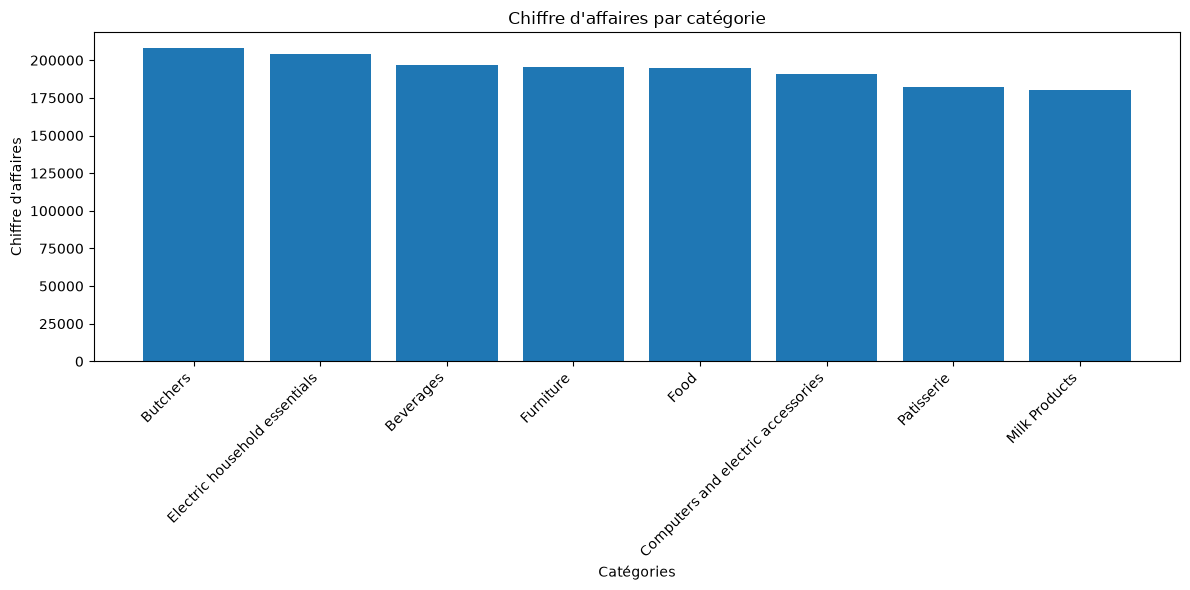

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(
    ventes_categorie["Category"],
    ventes_categorie["Chiffre_affaires"]
)

plt.title("Chiffre d'affaires par catégorie")
plt.xlabel("Catégories")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Enregistrer le graphique
plt.savefig("../figures/chiffre_affaires_par_categorie.png", dpi=300, bbox_inches="tight")

plt.show()

## 1.3 Évolution des ventes dans le temps

In [5]:
# Chiffre d'affaires et nombre de transactions par année
ventes_annee = df.groupby(df["Transaction Date"].dt.year).agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum")
)
ventes_annee.index.name = "Année"

display(ventes_annee)

,Nombre_transactions,Chiffre_affaires
Année,,
2022,4134,510329.5
2023,3987,491312.0
2024,4241,524881.0
2025,213,25548.5


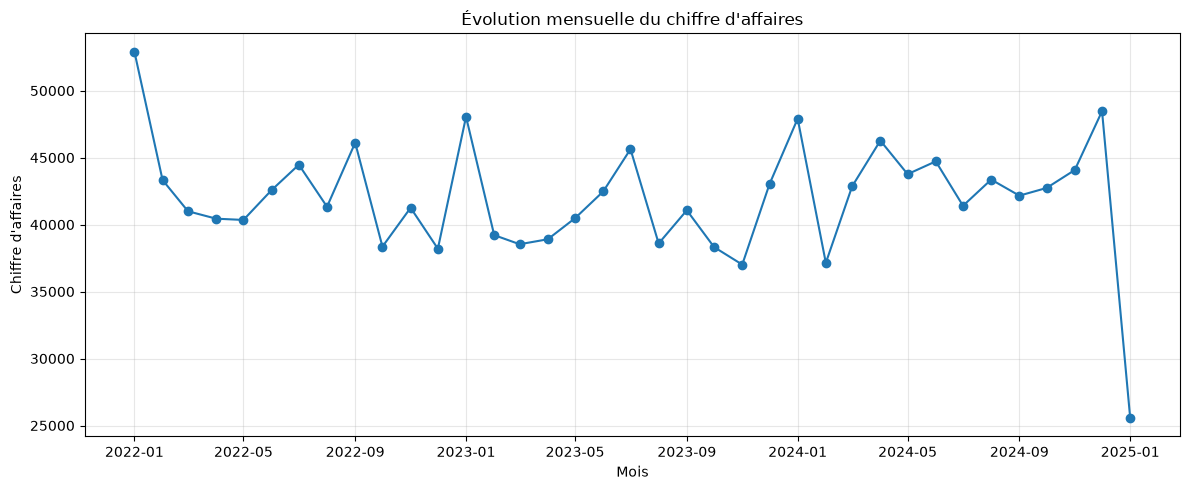

In [6]:
# Chiffre d'affaires par mois
ventes_mois = (
    df.set_index("Transaction Date")
    .resample("MS")["Total Spent"]
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(ventes_mois.index, ventes_mois.values, marker="o")

plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.grid(alpha=0.3)
plt.tight_layout()

# Enregistrer le graphique avant de l'afficher
plt.savefig("../figures/evolution_mensuelle_ca.png", dpi=300, bbox_inches="tight")
plt.show()

**Interprétation de l'évolution des ventes**

Le chiffre d'affaires est globalement stable sur les trois années complètes :

- 2022 : 510 330 (4 134 transactions)
- 2023 : 491 312 (3 987 transactions), soit une baisse de 3,7 %
- 2024 : 524 881 (4 241 transactions), soit une hausse de 6,8 %

2024 est la meilleure année, après un léger recul en 2023. Les écarts restent faibles : l'activité ne montre pas de tendance forte à la hausse ou à la baisse.

**Limite :** l'année 2025 ne compte que 213 transactions, car les données s'arrêtent en début d'année. Elle est incomplète et ne doit pas être comparée aux autres années. La baisse visible en fin de graphique ne correspond donc pas à une chute réelle des ventes.

## 1.4 Analyse des modes de paiement

In [7]:
# Nombre de transactions, chiffre d'affaires et panier moyen par mode de paiement
ventes_paiement = df.groupby("Payment Method").agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum"),
    Panier_moyen=("Total Spent", "mean")
).sort_values("Chiffre_affaires", ascending=False)

# Part de chaque mode dans le total des transactions
ventes_paiement["Part_transactions_%"] = (
    ventes_paiement["Nombre_transactions"]
    / ventes_paiement["Nombre_transactions"].sum() * 100
).round(1)

display(ventes_paiement.round(2))

,Nombre_transactions,Chiffre_affaires,Panier_moyen,Part_transactions_%
Payment Method,,,,
Cash,4310,537710.0,131.05,34.3
Digital Wallet,4144,507279.0,128.72,33.0
Credit Card,4121,507082.0,129.13,32.8


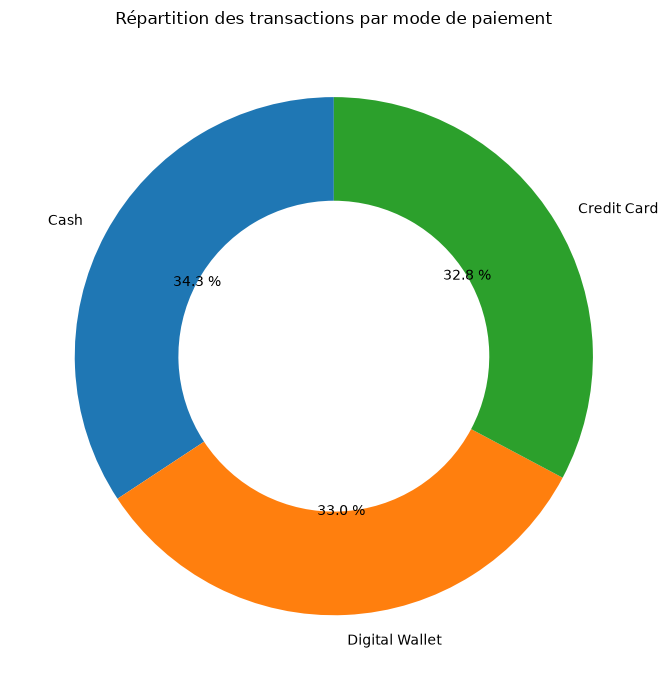

In [8]:
plt.figure(figsize=(7, 7))
plt.pie(
    ventes_paiement["Nombre_transactions"],
    labels=ventes_paiement.index,
    autopct="%1.1f %%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Répartition des transactions par mode de paiement")
plt.tight_layout()

plt.savefig("../figures/repartition_modes_paiement.png", dpi=300, bbox_inches="tight")
plt.show()

**Interprétation des modes de paiement**

Les trois modes de paiement sont utilisés de manière très équilibrée :

Le paiement en espèces arrive légèrement en tête, en nombre de transactions comme en chiffre d'affaires. Les écarts restent cependant faibles : moins de 2 points entre le premier et le dernier mode.

Le panier moyen est lui aussi très proche d'un mode à l'autre (entre 128,72 et 131,05). Le mode de paiement n'a donc pas d'influence notable sur le montant dépensé.

## 1.5 Ventes en ligne et en magasin

In [9]:
# Comparer les ventes en ligne et en magasin
ventes_canal = df.groupby("Location").agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum"),
    Panier_moyen=("Total Spent", "mean")
)

ventes_canal["Part_CA_%"] = (
    ventes_canal["Chiffre_affaires"]
    / ventes_canal["Chiffre_affaires"].sum() * 100
).round(1)

display(ventes_canal.round(2))

,Nombre_transactions,Chiffre_affaires,Panier_moyen,Part_CA_%
Location,,,,
In-store,6221,760670.0,128.86,49.0
Online,6354,791401.0,130.42,51.0


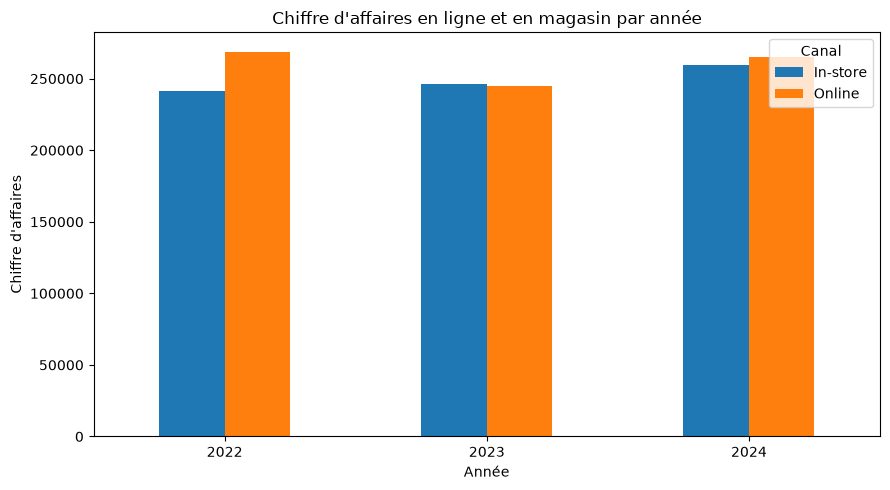

In [10]:
# Évolution annuelle du chiffre d'affaires par canal (hors 2025, année incomplète)
canal_annee = (
    df[df["Transaction Date"].dt.year < 2025]
    .groupby([df["Transaction Date"].dt.year, "Location"])["Total Spent"]
    .sum()
    .unstack()
)

canal_annee.plot(kind="bar", figsize=(9, 5))

plt.title("Chiffre d'affaires en ligne et en magasin par année")
plt.xlabel("Année")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=0)
plt.legend(title="Canal")
plt.tight_layout()

plt.savefig("../figures/ca_par_canal_et_annee.png", dpi=300, bbox_inches="tight")
plt.show()

**Interprétation des ventes en ligne et en magasin**

Les ventes sont réparties presque à parts égales entre les deux canaux 
La vente en ligne arrive légèrement en tête, avec un écart de 2 points seulement.

Le canal de vente n'a donc pas d'effet notable sur le comportement d'achat

## 1.6 Effet des remises

In [11]:
# Créer une colonne lisible : Oui, Non ou Inconnu
remise = df["Discount Applied"].map({True: "Oui", False: "Non"}).fillna("Inconnu")

ventes_remise = df.groupby(remise).agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum"),
    Panier_moyen=("Total Spent", "mean"),
    Quantite_moyenne=("Quantity", "mean")
)
ventes_remise.index.name = "Remise appliquée"

ventes_remise["Part_transactions_%"] = (
    ventes_remise["Nombre_transactions"]
    / ventes_remise["Nombre_transactions"].sum() * 100
).round(1)

display(ventes_remise.round(2))

,Nombre_transactions,Chiffre_affaires,Panier_moyen,Quantite_moyenne,Part_transactions_%
Remise appliquée,,,,,
Inconnu,4199,512492.5,128.51,5.49,33.4
Non,4157,515135.0,129.95,5.58,33.1
Oui,4219,524443.5,130.49,5.53,33.6


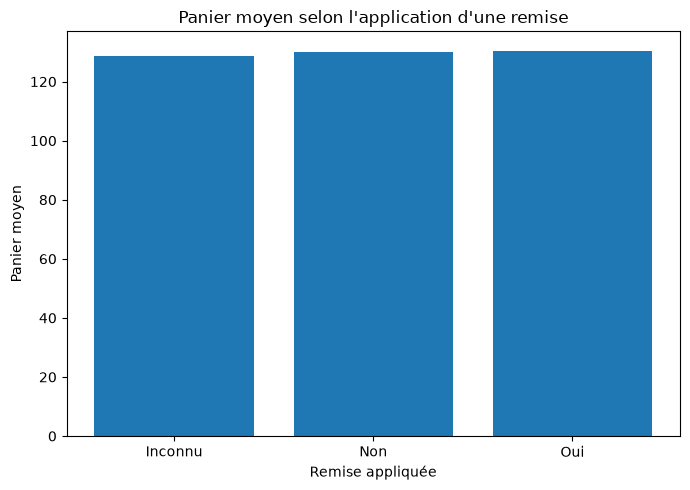

In [12]:
plt.figure(figsize=(7, 5))
plt.bar(ventes_remise.index, ventes_remise["Panier_moyen"])

plt.title("Panier moyen selon l'application d'une remise")
plt.xlabel("Remise appliquée")
plt.ylabel("Panier moyen")
plt.tight_layout()

plt.savefig("../figures/panier_moyen_remise.png", dpi=300, bbox_inches="tight")
plt.show()

**Interprétation de l'effet des remises**

Les transactions se répartissent en trois groupes de taille presque égale 

Le panier moyen est quasiment identique dans les trois groupes (entre 128,51 et 130,49), tout comme la quantité moyenne achetée (environ 5,5 articles). La remise ne semble donc pas inciter les clients à acheter davantage.

## 1.7 Meilleurs clients et produits

In [13]:
# Chiffre d'affaires par client
ventes_client = df.groupby("Customer ID").agg(
    Nombre_transactions=("Transaction ID", "nunique"),
    Chiffre_affaires=("Total Spent", "sum")
).sort_values("Chiffre_affaires", ascending=False)

ventes_client["Part_CA_%"] = (
    ventes_client["Chiffre_affaires"]
    / ventes_client["Chiffre_affaires"].sum() * 100
).round(1)

print("Top 5 des clients :")
display(ventes_client.head(5))

print("5 clients les moins rentables :")
display(ventes_client.tail(5))

Top 5 des clients :


,Nombre_transactions,Chiffre_affaires,Part_CA_%
Customer ID,,,
CUST_24,543,68452.0,4.4
CUST_08,533,67351.5,4.3
CUST_05,544,66974.5,4.3
CUST_16,515,65570.5,4.2
CUST_13,534,65037.0,4.2


5 clients les moins rentables :


,Nombre_transactions,Chiffre_affaires,Part_CA_%
Customer ID,,,
CUST_18,507,59142.0,3.8
CUST_01,507,58731.5,3.8
CUST_06,481,58632.5,3.8
CUST_17,487,57884.5,3.7
CUST_25,476,57155.5,3.7


**Interprétation des clients**

Le chiffre d'affaires est réparti de façon très homogène entre les 25 clients. Chacun représente entre 3,7 % et 4,4 % du total, très proche des 4 % qu'on obtiendrait avec une répartition parfaitement égale.

Le premier client (CUST_24) génère 68 452 de chiffre d'affaires avec 543 transactions, contre 57 156 pour le dernier (CUST_25) avec 476 transactions. Les écarts s'expliquent surtout par le nombre d'achats, et non par des paniers plus élevés.

L'entreprise ne dépend donc d'aucun client en particulier : la perte d'un client aurait un impact limité sur son activité.

,Item,Category,Total Spent
0,Item_25_FUR,Furniture,25625.0
1,Item_25_EHE,Electric household essentials,25502.0
2,Item_25_BUT,Butchers,22427.0
3,Item_24_FUR,Furniture,22080.5
4,Item_25_FOOD,Food,21771.0
5,Item_22_BUT,Butchers,21462.0
6,Item_23_BUT,Butchers,20596.0
7,Item_19_MILK,Milk Products,20448.0
8,Item_23_EHE,Electric household essentials,20178.0
9,Item_23_PAT,Patisserie,19684.0


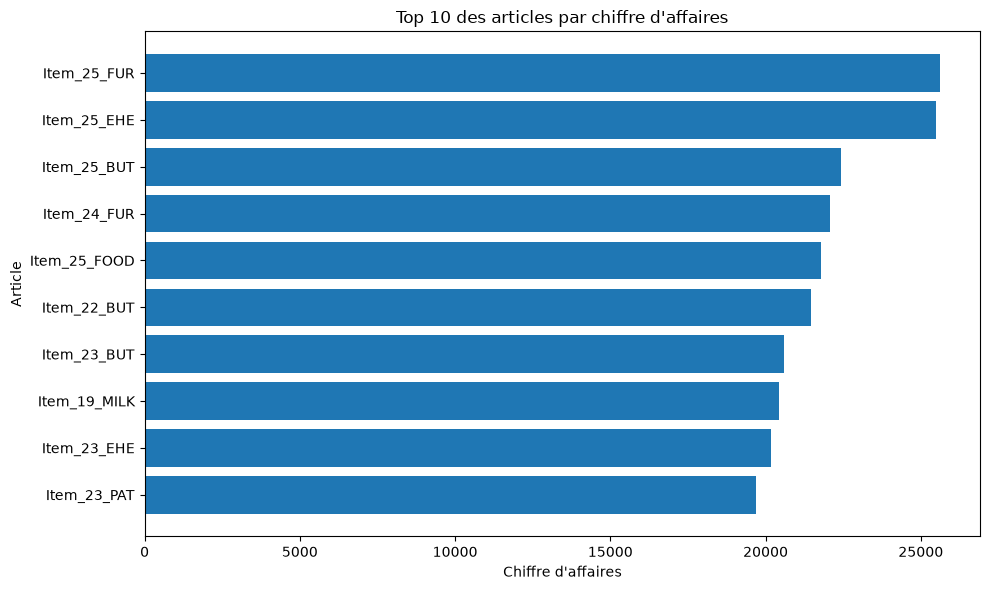

In [14]:
# Top 10 des articles par chiffre d'affaires
top_articles = (
    df.groupby(["Item", "Category"])["Total Spent"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_articles)

# Graphique en barres horizontales, le plus vendu en haut
plt.figure(figsize=(10, 6))
plt.barh(top_articles["Item"], top_articles["Total Spent"])
plt.gca().invert_yaxis()

plt.title("Top 10 des articles par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Article")
plt.tight_layout()

plt.savefig("../figures/top10_articles.png", dpi=300, bbox_inches="tight")
plt.show()

**Interprétation des articles**

L'article qui génère le plus de chiffre d'affaires est Item_25_FUR (Furniture), avec 25 625, suivi de près par Item_25_EHE (Electric household essentials), avec 25 502.

Le top 10 est largement dominé par les articles les plus chers (Item_22 à Item_25), présents dans plusieurs catégories : Item_25 apparaît trois fois dans les cinq premières places. Le chiffre d'affaires d'un article dépend donc surtout de son prix, plus que de sa catégorie.

La catégorie Butchers place trois articles dans le top 10 (Item_25_BUT, Item_22_BUT et Item_23_BUT), ce qui est cohérent avec sa première place en chiffre d'affaires par catégorie.

Seule exception : Item_19_MILK, moins cher, entre dans le top 10 grâce à un volume de ventes plus élevé.